In [1]:
import pandas as pd 
from stratified_dataset import question_scorer
import os
import numpy as np

# TOTAL ACC

In [2]:
pred = pd.read_csv("results.csv").rename(columns = {'final_answer' : 'system output'})
val = pd.read_json("stratified_dataset/60_task_subset_val.json")

#results dataframe
res =pd.merge(pred,val[['Final answer', 'task_id','Level']], on="task_id")

accuracy_list = []
for idx, row in res.iterrows():
    sys_out = str(row['system output']) if pd.notna(row['system output']) else "None"
    gt = row['Final answer']
    try:
        passed = question_scorer(model_answer=sys_out, ground_truth=gt)
    except Exception as e:
        passed = False

    accuracy_list.append({
        'task_id': row['task_id'],
        'Level': row['Level'],
        'config_id': row['config_id'],
        'passed': passed
    })

accuracy_df = pd.DataFrame(accuracy_list)

conf_accuracy_results = []
for i in range(1,9):
    df = accuracy_df[accuracy_df['config_id'] == i]

    lvl1 = df[df['Level'] == 1].passed.value_counts()[True]
    lvl2 = df[df['Level'] == 2].passed.value_counts()[True]
    conf_accuracy_results.append(
        {
            'config_id' : i,
            'lvl1_passed' : lvl1,
            'lvl2_passed' : lvl2,
            'total_passed_percentage' : str(round(((lvl1 + lvl2) /len(df)) * 100 , 2)) + "%"
        }
    )
conf_accuracy_results = pd.DataFrame(conf_accuracy_results)

Evaluating cornstarch, granulated sugar, lemon juice, ripe strawberries, vanilla extract as a comma separated list.
Evaluating 1 as a number.
Evaluating 89706.00 as a number.
Evaluating Bartek as a string.
Evaluating sklearn.utils.metaestimators as a string.
Evaluating 90 as a number.
Evaluating 0 as a number.
Evaluating Honolulu, Hawaii, Scranton, Pennsylvania as a comma separated list.
Evaluating 80GSFC21M0002 as a string.
Evaluating Annie Levin as a string.
Evaluating (A → B) ↔ (¬A ∨ B) as a string.
Evaluating 0.1777 as a number.
Evaluating 3/4,1/4,3/4,2/4,1/2,5/35,7/21,30/5,1/2,6/9,5/90,30/90,4/14,5/15,7/21,6/61,61/60,20/30 as a comma separated list.
Evaluating CUB as a string.
Evaluating None as a string.
Evaluating 500 Things To Eat Before It's Too Late: and the Very Best Places to Eat Them as a string.
Evaluating 4 as a number.
Evaluating 519 as a number.
Evaluating 27 as a number.
Evaluating 12 as a number.
Evaluating extremely as a string.
Evaluating Guatemala as a string.
Eva

/home/mike/Projects/clef-vs-qwen-orch/harness/stratified_dataset/official_gaia_scorer.py:56: UserWarning: Answer lists have different lengths, returning False.
  warnings.warn(


# ANALYSING LOGS

In [3]:
all_dfs = []
for conf in range(1, 9):
    folder_path = f"results/mas_{conf}"
    for filename in os.listdir(folder_path):
        if filename.endswith(".csv"):
            file_path = os.path.join(folder_path, filename)
            df_task = pd.read_csv(file_path)
            df_task["config_id"] = conf
            all_dfs.append(df_task)
master_df = pd.concat(all_dfs)
master_df.head()

,task_id,node,subagent_steps,state_step,tool_name,tool_args,confidence,probabilities,reasoning,compute_time_seconds,llm_tkns_in,llm_tkns_out,fdm_tkns_in,fdm_tkns_out,response,error,config_id
0,99c9cc74-fdc8-46c6-8f8d-3ce2d3bfeea3,orchestrator,NaN,1,NaN,NaN,0.8177,"{'web_search': 0.013, 'doc_reader': 0.0201, 'm...",NaN,1.023029,0,0,708,0,media_reader,NaN,1
1,99c9cc74-fdc8-46c6-8f8d-3ce2d3bfeea3,media_reader,1.0,2,transcribe_audio,"{""path"": ""data/gaia/99c9cc74-fdc8-46c6-8f8d-3c...",NaN,NaN,NaN,2.662994,1476,62,0,0,"Transcribed audio: In a saucepan, combine ripe...",NaN,1
2,99c9cc74-fdc8-46c6-8f8d-3ce2d3bfeea3,media_reader,2.0,2,NaN,NaN,NaN,NaN,NaN,1.859969,1634,33,0,0,"Based on the audio transcription, here are the...",NaN,1
3,99c9cc74-fdc8-46c6-8f8d-3ce2d3bfeea3,orchestrator,NaN,2,NaN,NaN,0.6371,"{'web_search': 0.0237, 'doc_reader': 0.0253, '...",NaN,0.714789,0,0,746,0,finalizer,NaN,1
4,99c9cc74-fdc8-46c6-8f8d-3ce2d3bfeea3,finalizer,NaN,3,NaN,NaN,NaN,NaN,False,1.825855,515,16,0,0,"cornstarch, granulated sugar, lemon juice, rip...",NaN,1


In [4]:
task_id_list = master_df.task_id.unique()
config_id_list = master_df.config_id.unique()
summary_records = []

for config in config_id_list:
    conf_df = master_df[master_df.config_id == config]

    task_latencies = []
    orch_latencies = []
    subagent_latencies = []
    task_llm_in = []
    task_llm_out = []
    task_fdm_in = []
    task_fdm_out = []
    task_state_steps = []
    task_subagent_steps = []

    for task in task_id_list:
        #x is the sub df for the given task in a given config
        x = conf_df[conf_df.task_id == task]

        #total Latency per task
        task_latencies.append(x.compute_time_seconds.sum())
        #orch Latency (node == 'orchestrator')
        orch_latencies.append(
            x[x.node == "orchestrator"].compute_time_seconds.sum()
        )
        #subagent Latency (node != 'orchestrator')
        subagent_latencies.append(
            x[x.node != "orchestrator"].compute_time_seconds.sum()
        )
        #tokens per task
        task_llm_in.append(x.llm_tkns_in.sum())
        task_llm_out.append(x.llm_tkns_out.sum())
        task_fdm_in.append(x.fdm_tkns_in.sum())
        task_fdm_out.append(x.fdm_tkns_out.sum())
        #state_step  is the orchestrator steps
        task_state_steps.append(x.state_step.max())
        # count subagent_steps
        task_subagent_steps.append(x.subagent_steps.notna().sum())
    

    #tool Error Rate per config
    
    has_error = conf_df.error.notna()
    
    total_steps = len(conf_df)
    total_errors = has_error.sum()
    general_error_rate = (total_errors / total_steps * 100)
    summary_records.append(
        {
            "config_id": config,

            "mean_total_latency_s": np.mean(task_latencies),
            "mean_orch_latency_s": np.mean(orch_latencies),
            "mean_subagent_latency_s": np.mean(subagent_latencies),
            
            "mean_llm_in_tokens": np.mean(task_llm_in),
            "mean_llm_out_tokens": np.mean(task_llm_out),
            "mean_fdm_in_tokens": np.mean(task_fdm_in),
            "mean_fdm_out_tokens": np.mean(task_fdm_out),

            "mean_state_steps": np.mean(task_state_steps),
            "mean_subagent_steps": np.mean(task_subagent_steps),

            "general_error_rate_pct": general_error_rate,
        }
    )
metrics_df = pd.DataFrame(summary_records)
metrics_df = pd.merge(metrics_df, conf_accuracy_results)

# COST IN CENTS

In [5]:
PRICE_LLM_IN = 0.08 / 1000000
PRICE_LLM_OUT = 0.13 / 1000000
PRICE_FDM_IN = 0.038 / 1000000


metrics_df["mean_llm_cost"] = (
    metrics_df["mean_llm_in_tokens"] * PRICE_LLM_IN
    + metrics_df["mean_llm_out_tokens"] * PRICE_LLM_OUT
) * 100
metrics_df["mean_fdm_cost"] = metrics_df["mean_fdm_in_tokens"] * PRICE_FDM_IN * 100
metrics_df["mean_cost"] = (
    metrics_df["mean_llm_cost"] + metrics_df["mean_fdm_cost"]
) 

metrics_df["total_benchmark_cost"] = metrics_df["mean_cost"] * 60

In [6]:
metrics_df.round(2)

,config_id,mean_total_latency_s,mean_orch_latency_s,mean_subagent_latency_s,mean_llm_in_tokens,mean_llm_out_tokens,mean_fdm_in_tokens,mean_fdm_out_tokens,mean_state_steps,mean_subagent_steps,general_error_rate_pct,lvl1_passed,lvl2_passed,total_passed_percentage,mean_llm_cost,mean_fdm_cost,mean_cost,total_benchmark_cost
0,1,45.43,1.91,43.52,45239.22,1247.70,1845.78,0.0,3.62,8.83,3.08,16,5,35.0%,0.38,0.01,0.39,23.11
1,2,72.78,4.67,68.11,58988.73,1277.33,0.00,0.0,3.53,9.77,5.14,12,3,25.0%,0.49,0.00,0.49,29.31
2,3,126.30,28.95,97.35,54226.25,2954.32,0.00,0.0,3.42,8.32,3.27,15,4,31.67%,0.47,0.00,0.47,28.33
3,4,423.99,5.73,418.26,56935.53,13142.40,41431.88,0.0,4.70,14.90,21.85,12,6,30.0%,0.63,0.16,0.78,47.03
4,5,102.16,3.65,98.51,41166.02,2123.47,29627.65,0.0,3.80,11.05,14.14,12,5,28.33%,0.36,0.11,0.47,28.17
5,6,89.59,5.28,84.31,28055.62,2476.43,0.00,0.0,4.92,8.80,0.24,13,5,30.0%,0.26,0.00,0.26,15.40
6,7,65.22,1.68,63.54,35396.48,1543.52,31702.68,0.0,4.03,10.65,15.44,9,5,23.33%,0.30,0.12,0.42,25.42
7,8,137.92,49.50,88.42,36074.08,4349.43,0.00,0.0,5.02,10.33,1.74,15,5,33.33%,0.35,0.00,0.35,20.71


<Axes: xlabel='mean_cost', ylabel='total_passed_percentage'>

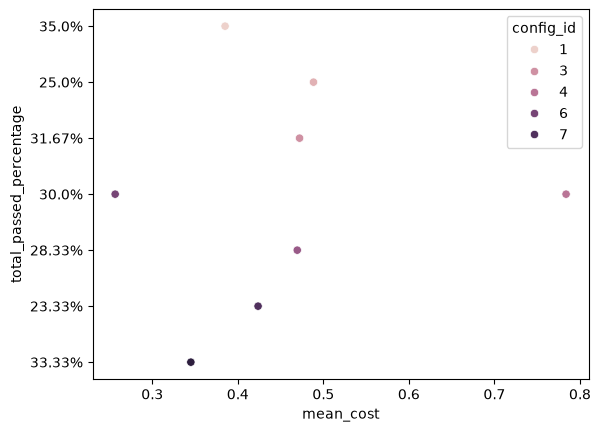

In [7]:
import seaborn as sns
# Acc vs Cost
sns.scatterplot(data=metrics_df, x="mean_cost", y="total_passed_percentage", hue="config_id")